# 06. Grafo principal y subgrafo de coautoría

Esta libreta construye los dos grafos a partir de `Canonico_FINAL.csv`.
Cada fila del archivo corresponde a un artículo y un autor. El esquema sigue las diapositivas 6–15 de **Link-Prediction-BDUNAM**.

| Grafo | Nodos | Aristas |
|---|---|---|
| Principal | Artículo, autor, afiliación y keyword | Autor–artículo, autor–afiliación y artículo–keyword |
| Coautoría | Autores, con sus afiliaciones como atributos | Dos autores que aparecen en un mismo artículo |

Ambos son **no dirigidos**.

## 1. Bibliotecas

Se utilizan pandas para leer el CSV, NetworkX para construir y guardar los grafos y Matplotlib para dibujarlos. NumPy y SciPy apoyan la distribución visual.

In [1]:
import json
from collections import Counter
from hashlib import sha256
from itertools import combinations

import pandas as pd
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# La semilla permite repetir la distribución visual con el mismo entorno.
SEMILLA = 42
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})

print(f"pandas {pd.__version__} | NetworkX {nx.__version__}")

pandas 2.3.3 | NetworkX 3.6.1


## 2. Lectura del archivo

Se lee el archivo canónico directamente porque contiene las afiliaciones de cada autor en cada artículo.

In [2]:
for base in ("./", "../"):
    ruta_csv = base + "04_Limpieza/06_Finales/Canonico_FINAL.csv"
    try:
        datos = pd.read_csv(ruta_csv, dtype=str, keep_default_na=False,
                            encoding="utf-8-sig")
        carpeta_salida = base + "06_grafos/"
        break
    except FileNotFoundError:
        continue
else:
    raise FileNotFoundError(
        "Revisa el nombre del archivo y la ubicación de la libreta."
    )

with open(ruta_csv, "rb") as archivo:
    huella_csv = sha256(archivo.read()).hexdigest()

print("Entrada:", ruta_csv)
print("Salidas:", carpeta_salida)
print(f"Filas: {len(datos):,}")
print("SHA-256:", huella_csv)
display(datos[["indice", "Titulo", "Autor_norm", "Afiliacion1"]].head(3))

Entrada: ../04_Limpieza/06_Finales/Canonico_FINAL.csv
Salidas: ../06_grafos/
Filas: 1,151
SHA-256: 83547be2ffabaf81877332a3963ebb28b7b25dd7d5596296f289180e60090bc5


,indice,Titulo,Autor_norm,Afiliacion1
0,1,A comparative study of NeuralODE and Universal...,Raymundo Vazquez Martinez,Universidad Nacional Autónoma de México
1,2,A Comparative Study of Numerical Laplace Inver...,Vladimir Martínez Bernardino,Universidad Nacional Autónoma de México
2,3,A Greenfield Analysis for Supply Chains Enhanc...,Jose Antonio Marmolejo Saucedo,Facultad de Ingeniería


## 3. Revisión de los campos necesarios

`indice` identifica al artículo y `Autor_norm` identifica al autor dentro de esta base. Los nombres se usan exactamente como están escritos.

In [3]:
columnas = ["indice", "Titulo", "Año", "Autor_norm", "Afiliacion1", "Afiliacion2",
            "ISBN", "ISSN", "Doi", "URL", "Area", "SubArea", "Keywords", "Abstract"]
faltantes = sorted(set(columnas) - set(datos.columns))
if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

for columna in ("indice", "Titulo", "Año", "Autor_norm"):
    if datos[columna].str.strip().eq("").any():
        raise ValueError(f"Hay celdas vacías en {columna}; deben revisarse antes de crear el grafo.")

for columna in ("indice", "Año"):
    if not datos[columna].str.fullmatch(r"[0-9]+").all():
        raise ValueError(f"{columna} debe contener enteros escritos sin decimales.")

# Un par repetido podría ocultar información distinta de afiliación.
if datos.duplicated(["indice", "Autor_norm"]).any():
    raise ValueError("Hay pares indice–Autor_norm repetidos. Revisa esas filas antes de continuar.")

campos_articulo = [c for c in columnas if c not in
                   ["indice", "Autor_norm", "Afiliacion1", "Afiliacion2"]]
conflictos = datos.groupby("indice")[campos_articulo].nunique().gt(1)
if conflictos.any().any():
    display(conflictos.loc[conflictos.any(axis=1)])
    raise ValueError("Un mismo indice tiene valores bibliográficos diferentes.")

# Las filas de autores distintos ya coinciden en los atributos del artículo.
articulos = datos.drop_duplicates("indice").copy()
print(f"Artículos por indice: {len(articulos):,}")
print(f"Autores por Autor_norm: {datos['Autor_norm'].nunique():,}")
print("Artículos por año:", articulos["Año"].value_counts().sort_index().to_dict())

# Los títulos iguales no son la identidad del nodo: cada indice se conserva.
titulos_repetidos = articulos.loc[
    articulos["Titulo"].duplicated(keep=False), ["indice", "Titulo", "Doi"]
]
if not titulos_repetidos.empty:
    print("Hay títulos iguales con índices distintos. Se conservan todos los índices:")
    display(titulos_repetidos.sort_values("Titulo"))

Artículos por indice: 519
Autores por Autor_norm: 628
Artículos por año: {'2024': 236, '2025': 283}
Hay títulos iguales con índices distintos. Se conservan todos los índices:


,indice,Titulo,Doi
1076,474,Asynchronous Fault-Tolerant Language Decidabil...,10.1145/3732772.3733514
1078,475,Asynchronous Fault-Tolerant Language Decidabil...,10.48550/arxiv.2502.00191
864,389,Cloud Detection using Night Sky Background Lig...,10.22323/1.501.0408
865,390,Cloud Detection using Night Sky Background Lig...,10.48550/arxiv.2509.06343
679,304,Expanding the Pierre Auger Observatory Open Da...,10.22323/1.501.1251
680,305,Expanding the Pierre Auger Observatory Open Da...,10.48550/arxiv.2507.08504
416,200,La Leaderboard: A Large Language Model Leaderb...,10.18653/v1/2025.acl-long.1561
417,201,La Leaderboard: A Large Language Model Leaderb...,10.48550/arxiv.2507.00999


## 4. Reglas de construcción

- Un nodo de artículo por `indice`, aunque varios índices tengan el mismo título.
- Un nodo de autor por valor exacto de `Autor_norm`.
- Un nodo de afiliación por nombre no vacío de `Afiliacion1` y `Afiliacion2`.
- Las keywords se separan únicamente por **punto y coma (`;`)**. Se retiran los
  espacios exteriores de cada elemento y se descartan elementos vacíos o repetidos.
  Se conservan mayúsculas, acentos y signos de puntuación.
- Los prefijos `articulo:`, `autor:`, `afiliacion:` y `keyword:` evitan que un
  mismo texto usado en dos tipos de nodo se mezcle.
- Se conservan todos los artículos y autores del CSV. Los faltantes bibliográficos
  permanecen como cadenas vacías y no generan nodos vacíos.

Los atributos usan claves sin acentos para exportarse a GML, por ejemplo `anio`
para la columna `Año`. **Los valores conservan sus acentos y texto completo**.
Las listas de afiliaciones e índices se guardan como texto JSON y se pueden
recuperar con `json.loads(...)`.

In [4]:
def separar_keywords(texto):
    """Devuelve keywords únicas, respetando su escritura y su orden."""
    return list(dict.fromkeys(p.strip() for p in texto.split(";") if p.strip()))


def lista_json(valores):
    """Conserva una lista como texto para guardarla sin ambigüedad en GML."""
    return json.dumps(list(valores), ensure_ascii=False)


G_principal = nx.Graph(
    nombre="Grafo bibliográfico principal",
    fuente="04_Limpieza/06_Finales/Canonico_FINAL.csv",
    sha256=huella_csv,
    criterioArticulo="Un nodo por indice del CSV",
    criterioAutor="Coincidencia exacta de Autor_norm",
    criterioKeyword="Separación por punto y coma; se conserva la escritura"
)

## 5. Artículos y keywords

Los artículos conservan título, año, ISBN, ISSN, DOI, URL, área, subárea,
keywords originales y abstract completo. Un artículo sin keywords permanece
en el grafo y después se conecta con sus autores.

In [5]:
# Correspondencia entre las columnas del CSV y los atributos del artículo.
campos_grafo = {
    "Titulo": "titulo", "Año": "anio", "ISBN": "isbn", "ISSN": "issn",
    "Doi": "doi", "URL": "url", "Area": "area", "SubArea": "subarea",
    "Keywords": "keywords", "Abstract": "abstract"
}

for fila in articulos.to_dict("records"):
    nodo_articulo = "articulo:" + fila["indice"]
    atributos = {destino: fila[origen] for origen, destino in campos_grafo.items()}
    atributos["anio"] = int(fila["Año"])
    atributos["indice"] = int(fila["indice"])

    G_principal.add_node(nodo_articulo, tipo="articulo", nombre=fila["Titulo"], **atributos)

    # Las keywords iguales comparten un nodo, con una arista por artículo.
    for palabra in separar_keywords(fila["Keywords"]):
        nodo_keyword = "keyword:" + palabra
        G_principal.add_node(nodo_keyword, tipo="keyword", nombre=palabra)
        G_principal.add_edge(nodo_articulo, nodo_keyword, tipo="keyword")

print("Artículos y keywords incorporados.")

Artículos y keywords incorporados.


## 6. Autores, afiliaciones y autoría

Para cada autor se reúnen **todas las afiliaciones observadas** en sus filas.
Un autor puede acumular más de dos afiliaciones al considerar todos sus artículos.
Cada arista autor–afiliación conserva los índices donde aparece esa afiliación.
Además, la arista autor–artículo conserva `afiliacion1` y `afiliacion2` de la
fila original, para consultar qué afiliación se registró en ese artículo.

In [6]:
for nombre, filas in datos.groupby("Autor_norm", sort=True):
    nodo_autor = "autor:" + nombre
    afiliaciones = sorted((set(filas["Afiliacion1"]) | set(filas["Afiliacion2"])) - {""})
    indices = sorted(int(i) for i in filas["indice"].unique())

    G_principal.add_node(
        nodo_autor, tipo="autor", nombre=nombre,
        afiliaciones=lista_json(afiliaciones),
        articulos=lista_json(indices), numeroArticulos=len(indices)
    )

    for afiliacion in afiliaciones:
        nodo_afiliacion = "afiliacion:" + afiliacion
        G_principal.add_node(nodo_afiliacion, tipo="afiliacion", nombre=afiliacion)
        # Se registran los artículos que respaldan esta afiliación del autor.
        aparece = filas["Afiliacion1"].eq(afiliacion) | filas["Afiliacion2"].eq(afiliacion)
        indices_afiliacion = sorted(int(i) for i in filas.loc[aparece, "indice"].unique())
        G_principal.add_edge(nodo_autor, nodo_afiliacion, tipo="afiliacion",
                             articulos=lista_json(indices_afiliacion))

# Cada fila crea la arista entre su artículo y su autor.
for fila in datos.to_dict("records"):
    G_principal.add_edge(
        "autor:" + fila["Autor_norm"], "articulo:" + fila["indice"], tipo="autoria",
        afiliacion1=fila["Afiliacion1"], afiliacion2=fila["Afiliacion2"]
    )

print(f"Grafo principal: {G_principal.number_of_nodes():,} nodos y "
      f"{G_principal.number_of_edges():,} aristas.")

Grafo principal: 7,129 nodos y 10,537 aristas.


## 7. Subgrafo de coautoría

Primero se agregan todos los autores, incluidos los que quedarán aislados. Después, por cada artículo, se conectan todas las parejas de autores distintos. Compartir afiliación o keyword no genera una arista de coautoría.

El atributo `weight` cuenta **índices de artículo compartidos**. Cada pareja tiene una sola arista, aunque comparta varios artículos. El atributo `articulos` permite consultar cuáles sustentan esa arista. Si se conservaron versiones editorial y preprint con índices distintos, ambas cuentan por separado en ese peso.

El atributo `grado` cuenta **coautores distintos**, sin sumar repeticiones de artículos. Un autor aislado no tiene coautores registrados dentro del CSV; esto no permite concluir que carezca de colaboradores fuera de la base.

In [8]:
G_coautoria = nx.Graph(
    nombre="Subgrafo de coautoría",
    fuente=G_principal.graph["fuente"], sha256=huella_csv,
    criterio="Proyección sobre autores por indice de artículo compartido",
    significadoPeso="Número de índices de artículo compartidos"
)

# Copiamos los autores y sus atributos, incluso si no tendrán vecinos.
autores = [n for n, a in G_principal.nodes(data=True) if a["tipo"] == "autor"]
G_coautoria.add_nodes_from((n, dict(G_principal.nodes[n])) for n in autores)

for indice in articulos["indice"]:
    # Solo se toman los vecinos de tipo autor de este artículo.
    coautores = sorted(n for n in G_principal.neighbors("articulo:" + indice)
                       if G_principal.nodes[n]["tipo"] == "autor")
    for autor1, autor2 in combinations(coautores, 2):
        if not G_coautoria.has_edge(autor1, autor2):
            G_coautoria.add_edge(autor1, autor2, tipo="coautoria", weight=0, articulos=[])
        arista = G_coautoria[autor1][autor2]
        arista["weight"] += 1
        arista["articulos"].append(int(indice))

# Convertimos las listas a texto JSON antes de guardar el grafo.
for _, _, atributos in G_coautoria.edges(data=True):
    atributos["articulos"] = lista_json(sorted(atributos["articulos"]))

for autor in G_coautoria:
    G_coautoria.nodes[autor]["grado"] = G_coautoria.degree(autor)

print(f"Coautoría: {G_coautoria.number_of_nodes():,} autores y "
      f"{G_coautoria.number_of_edges():,} parejas distintas.")

Coautoría: 628 autores y 1,121 parejas distintas.


## 8. Resumen y comprobaciones

Los conteos se calculan a partir de los grafos recién construidos.

In [9]:
conteo_nodos = Counter(a["tipo"] for _, a in G_principal.nodes(data=True))
conteo_aristas = Counter(a["tipo"] for _, _, a in G_principal.edges(data=True))
aislados = list(nx.isolates(G_coautoria))
componentes = list(nx.connected_components(G_coautoria))

assert not G_principal.is_directed() and not G_coautoria.is_directed()
assert nx.number_of_selfloops(G_principal) == 0
assert nx.number_of_selfloops(G_coautoria) == 0
assert conteo_nodos["articulo"] == datos["indice"].nunique()
assert G_coautoria.number_of_nodes() == datos["Autor_norm"].nunique()
assert conteo_aristas["autoria"] == len(datos)

resumen = pd.DataFrame([
    ["Principal", "Artículos", conteo_nodos["articulo"]],
    ["Principal", "Autores", conteo_nodos["autor"]],
    ["Principal", "Afiliaciones", conteo_nodos["afiliacion"]],
    ["Principal", "Keywords", conteo_nodos["keyword"]],
    ["Principal", "Nodos totales", G_principal.number_of_nodes()],
    ["Principal", "Aristas de autoría", conteo_aristas["autoria"]],
    ["Principal", "Aristas de afiliación", conteo_aristas["afiliacion"]],
    ["Principal", "Aristas de keyword", conteo_aristas["keyword"]],
    ["Principal", "Aristas totales", G_principal.number_of_edges()],
    ["Coautoría", "Autores", G_coautoria.number_of_nodes()],
    ["Coautoría", "Parejas distintas", G_coautoria.number_of_edges()],
    ["Coautoría", "Autores aislados", len(aislados)],
    ["Coautoría", "Componentes conexos", len(componentes)],
    ["Coautoría", "Autores del componente mayor", max(map(len, componentes), default=0)],
    ["Coautoría", "Suma de pesos", sum(a["weight"] for _, _, a in G_coautoria.edges(data=True))]
], columns=["Grafo", "Medida", "Cantidad"])
display(resumen)

,Grafo,Medida,Cantidad
0,Principal,Artículos,519
1,Principal,Autores,628
2,Principal,Afiliaciones,83
3,Principal,Keywords,5899
4,Principal,Nodos totales,7129
5,Principal,Aristas de autoría,1151
6,Principal,Aristas de afiliación,705
7,Principal,Aristas de keyword,8681
8,Principal,Aristas totales,10537
9,Coautoría,Autores,628


## 9. Guardar los dos grafos completos

Se utiliza **GML**. Estos archivos guardan nodos, aristas y atributos para continuar el trabajo con NetworkX o abrirlos en una aplicación que admita ese formato. Las imágenes de las siguientes celdas son vistas generales de los mismos grafos.

In [10]:
nx.write_gml(G_principal, carpeta_salida + "grafo_principal.gml")
nx.write_gml(G_coautoria, carpeta_salida + "subgrafo_coautoria.gml")
print("Guardados: grafo_principal.gml y subgrafo_coautoria.gml")

Guardados: grafo_principal.gml y subgrafo_coautoria.gml


## 10. Imagen del grafo principal

La imagen incluye **todos los nodos y todas las aristas**. Las etiquetas completas se consultan en el archivo GML, porque superponer miles de textos haría ilegible la vista general.

Para reducir el tiempo del dibujo, primero se distribuyen artículos, autores y afiliaciones. Luego se sitúan las keywords cerca del promedio de las posiciones de sus artículos. Las posiciones son auxiliares de dibujo: no representan distancia geográfica ni una medida de similitud semántica.

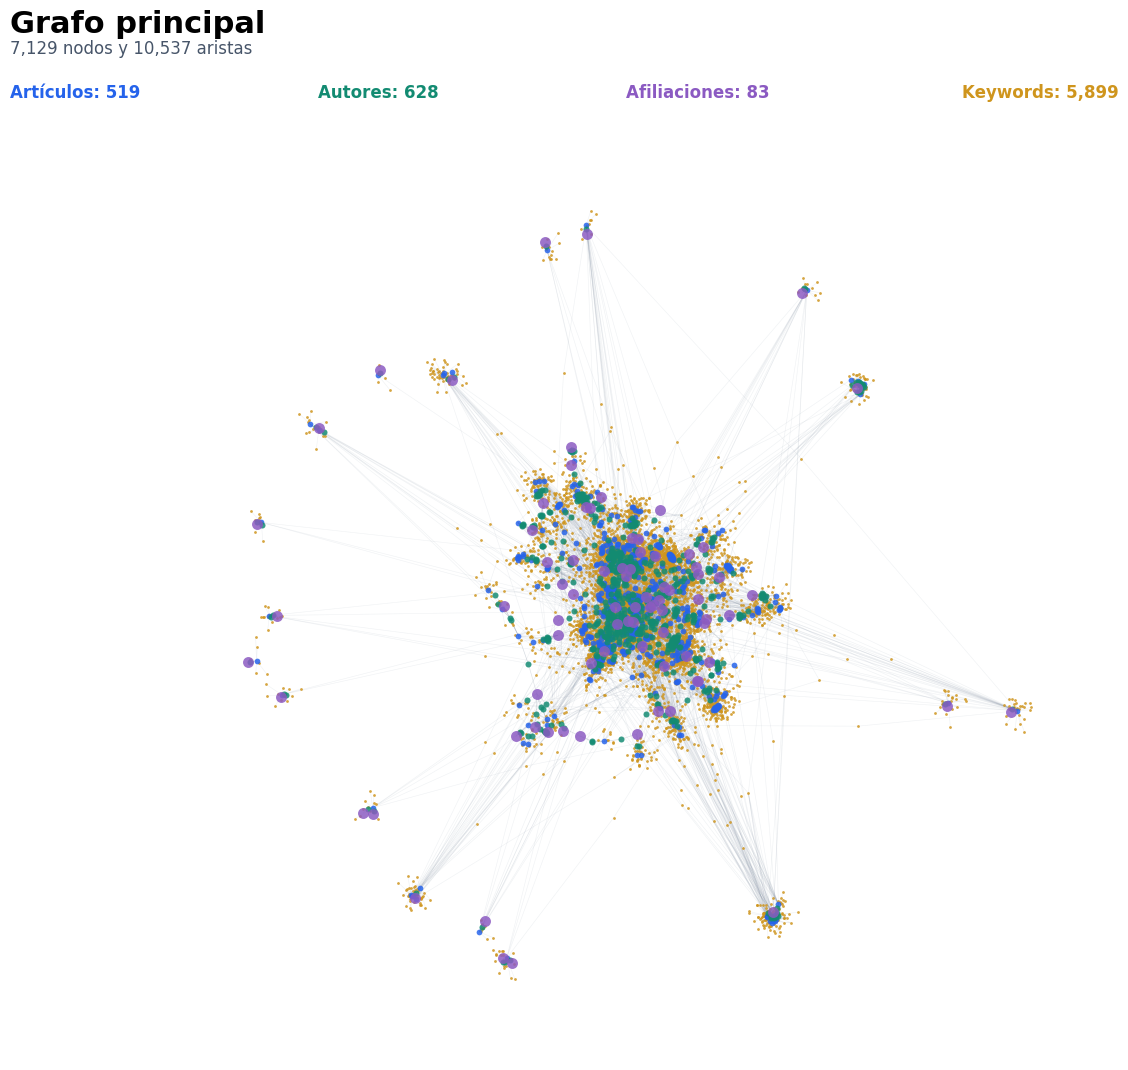

In [11]:
colores = {"articulo": "#2563EB", "autor": "#138B72",
           "afiliacion": "#8B5AC2", "keyword": "#CF951D"}
tamanos = {"articulo": 17, "autor": 19, "afiliacion": 62, "keyword": 4}
nombres_tipo = {"articulo": "Artículos", "autor": "Autores",
                "afiliacion": "Afiliaciones", "keyword": "Keywords"}

# Se calcula la distribución sobre los tres tipos que forman el núcleo.
nucleo = G_principal.subgraph(n for n, a in G_principal.nodes(data=True)
                             if a["tipo"] != "keyword")
pos_principal = nx.spring_layout(nucleo, seed=SEMILLA, iterations=90, weight=None)
azar = np.random.default_rng(SEMILLA)

for nodo, atributos in G_principal.nodes(data=True):
    if atributos["tipo"] == "keyword":
        posiciones_articulos = [pos_principal[v] for v in G_principal.neighbors(nodo)]
        centro = np.mean(posiciones_articulos, axis=0)
        pos_principal[nodo] = centro + azar.normal(0, 0.018, size=2)

fig, ax = plt.subplots(figsize=(14, 11), facecolor="white")
for tipo, transparencia in [("keyword", 0.10), ("autoria", 0.30), ("afiliacion", 0.24)]:
    aristas = [(u, v) for u, v, a in G_principal.edges(data=True) if a["tipo"] == tipo]
    nx.draw_networkx_edges(G_principal, pos_principal, edgelist=aristas, ax=ax,
                           edge_color="#718096", alpha=transparencia, width=0.45)

# Dibujamos primero keywords y después los tipos con menos nodos.
for tipo in ("keyword", "articulo", "autor", "afiliacion"):
    nodos = [n for n, a in G_principal.nodes(data=True) if a["tipo"] == tipo]
    nx.draw_networkx_nodes(G_principal, pos_principal, nodelist=nodos, ax=ax,
                           node_color=colores[tipo], node_size=tamanos[tipo],
                           linewidths=0, alpha=0.84)

fig.suptitle("Grafo principal", x=0.05, y=0.98, ha="left", fontsize=22, fontweight="bold")
fig.text(0.05, 0.94, f"{len(G_principal):,} nodos y {G_principal.number_of_edges():,} aristas",
         ha="left", color="#475569", fontsize=12)
for x, tipo in zip([0.05, 0.27, 0.49, 0.73], ["articulo", "autor", "afiliacion", "keyword"]):
    fig.text(x, 0.90, f"{nombres_tipo[tipo]}: {conteo_nodos[tipo]:,}",
             color=colores[tipo], fontsize=12, fontweight="bold")
ax.set_axis_off()
ax.set_aspect("equal")
fig.subplots_adjust(left=0.025, right=0.975, bottom=0.025, top=0.87)
fig.savefig(carpeta_salida + "grafo_principal.png", dpi=220, facecolor="white")
plt.show()
plt.close(fig)

## 11. Imagen del subgrafo de coautoría

La vista incluye todos los autores, también los aislados (en gris). El tamaño del nodo aumenta con el número de coautores distintos. El grosor de la arista aumenta con el número de índices de artículo compartidos. La disposición visual no expresa una probabilidad de colaboración futura.

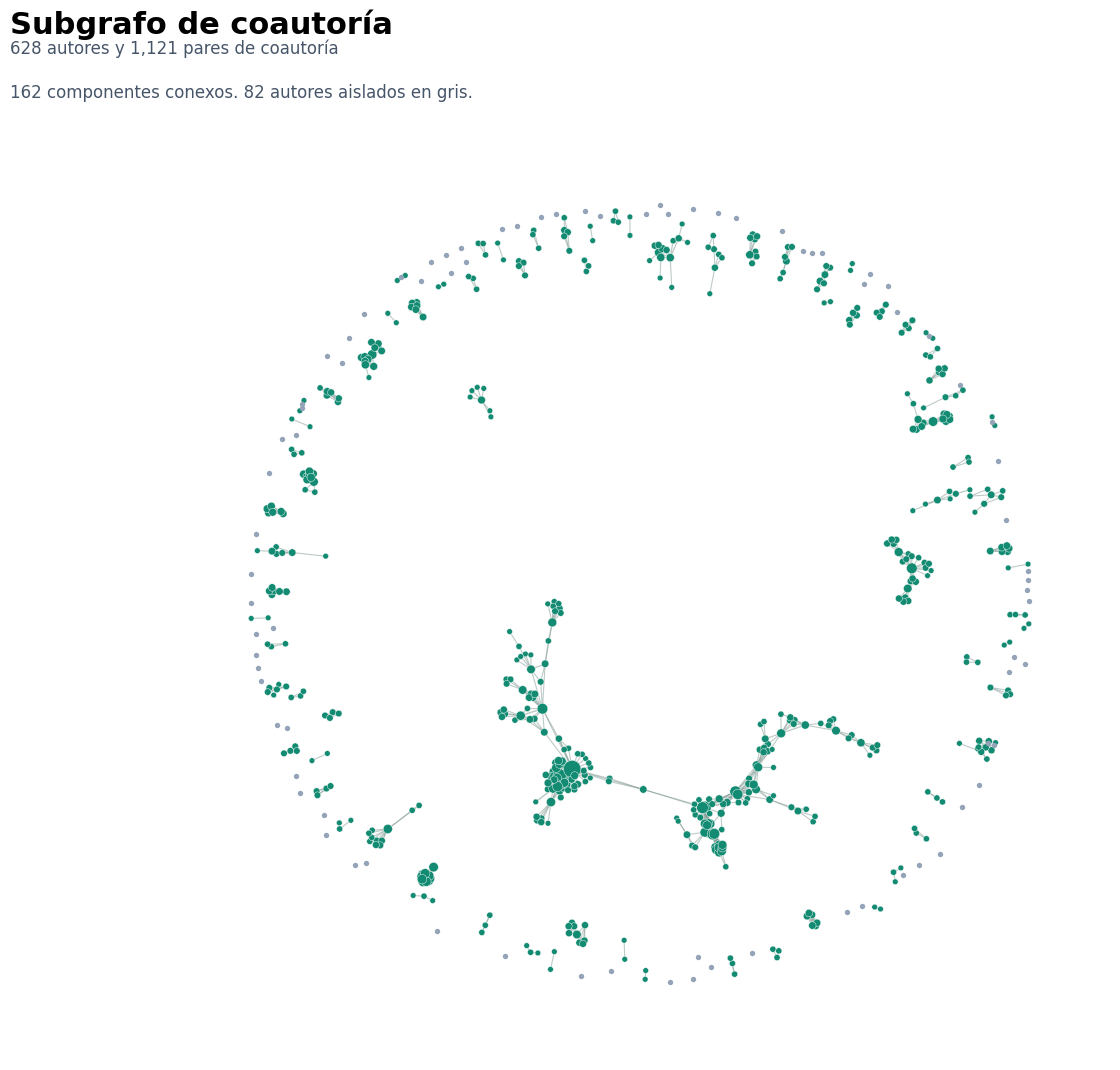

In [12]:
# weight=None deja los pesos fuera del cálculo de posiciones.
# El peso sí se representa en el grosor de cada arista.
pos_coautoria = nx.spring_layout(G_coautoria, seed=SEMILLA, iterations=180,
                                 k=0.16, weight=None)
con_coautoria = [n for n in G_coautoria if G_coautoria.degree(n) > 0]
grosores = [0.45 + 0.35 * np.sqrt(a["weight"]) for _, _, a in G_coautoria.edges(data=True)]

fig, ax = plt.subplots(figsize=(14, 11), facecolor="white")
nx.draw_networkx_edges(G_coautoria, pos_coautoria, ax=ax, width=grosores,
                       edge_color="#7D9690", alpha=0.50)
nx.draw_networkx_nodes(G_coautoria, pos_coautoria, nodelist=con_coautoria, ax=ax,
                       node_size=[14 + 3 * G_coautoria.degree(n) for n in con_coautoria],
                       node_color=colores["autor"], linewidths=0.3, edgecolors="white")
nx.draw_networkx_nodes(G_coautoria, pos_coautoria, nodelist=aislados, ax=ax,
                       node_size=15, node_color="#94A3B8", linewidths=0)

fig.suptitle("Subgrafo de coautoría", x=0.05, y=0.98, ha="left", fontsize=22, fontweight="bold")
fig.text(0.05, 0.94, f"{len(G_coautoria):,} autores y {G_coautoria.number_of_edges():,} pares de coautoría",
         ha="left", color="#475569", fontsize=12)
fig.text(0.05, 0.90, f"{len(componentes):,} componentes conexos. {len(aislados):,} autores aislados en gris.",
         ha="left", color="#475569", fontsize=12)
ax.set_axis_off()
ax.set_aspect("equal")
fig.subplots_adjust(left=0.025, right=0.975, bottom=0.025, top=0.87)
fig.savefig(carpeta_salida + "subgrafo_coautoria.png", dpi=220, facecolor="white")
plt.show()
plt.close(fig)

## 12. Volver a abrir los archivos

Esta celda comprueba que ambos GML se pueden volver a leer y muestra un ejemplo real de una arista de coautoría con sus artículos de respaldo.

In [11]:
principal_guardado = nx.read_gml(carpeta_salida + "grafo_principal.gml")
coautoria_guardada = nx.read_gml(carpeta_salida + "subgrafo_coautoria.gml")

for original, cargado in [(G_principal, principal_guardado), (G_coautoria, coautoria_guardada)]:
    assert original.number_of_nodes() == cargado.number_of_nodes()
    assert original.number_of_edges() == cargado.number_of_edges()

print("Los dos grafos se guardaron y se volvieron a leer correctamente.")
if coautoria_guardada.number_of_edges():
    autor1, autor2, arista = max(coautoria_guardada.edges(data=True), key=lambda x: x[2]["weight"])
    print("Ejemplo de coautoría:")
    print("Autor 1:", coautoria_guardada.nodes[autor1]["nombre"])
    print("Autor 2:", coautoria_guardada.nodes[autor2]["nombre"])
    print("Índices compartidos:", json.loads(arista["articulos"]))
    print("Peso:", arista["weight"])

Los dos grafos se guardaron y se volvieron a leer correctamente.
Ejemplo de coautoría:
Autor 1: Boris Escalante Ramírez
Autor 2: Jimena Olveres Montiel
Índices compartidos: [18, 19, 101, 105, 134, 137, 164, 193, 218, 261, 323, 396, 398, 412, 417, 434, 437]
Peso: 17
